# First PyTorch MLP: citywide hourly ride starts
This is an **educational, exploratory development experiment** on January–February 2024: 1,440 hours and 4,006,382 accepted rides. The February test period has already been inspected in earlier experiments; it is not an untouched final benchmark. The final January 2024–December 2025 dataset specification remains unchanged.

We use the same nine features, chronological splits and next-24-elapsed-hour forecast contract as XGBoost. The architecture is **9 → 32 ReLU → 16 ReLU → 1**, predicting one hourly demand value for each feature row. Twenty-four rows form one midnight-issued forecast.

## Environment
Use the existing **CityPulse AI (.venv)** kernel. Install with `.venv/bin/python -m pip install -e '.[neural,forecasting,notebooks,dev]'` from the project root. We use CPU, float32, fixed seeds and one CPU thread. This notebook reads only existing validated local outputs. No raw ETL, downloads or cloud operations run.

On this Mac, keep the existing XGBoost OpenMP launch setting when starting Jupyter:
```bash
export DYLD_LIBRARY_PATH="$PWD/.venv/lib/python3.14/site-packages/sklearn/.dylibs${DYLD_LIBRARY_PATH:+:$DYLD_LIBRARY_PATH}"
.venv/bin/python -m jupyter lab
```
Python 3.14.7 and the existing environment were retained; PyTorch 2.14.1 has a matching macOS ARM wheel.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, sklearn
from IPython.display import display, Markdown
from citypulse_ai.forecasting.experiment import load_development_citywide, START, END
from citypulse_ai.forecasting.baselines import LOCAL_ZONE, evaluate_midnights
from citypulse_ai.forecasting.xgboost_model import (
    FEATURES, VALIDATION_START, TEST_START, forecast_features, forecast_next_day,
)
from citypulse_ai.forecasting.mlp import run_mlp_experiment, load_mlp
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
versions = {'torch': str(torch.__version__), 'sklearn': sklearn.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__}
display(versions)
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})

{'torch': '2.14.1', 'sklearn': '1.9.1', 'numpy': '2.5.3', 'pandas': '3.0.6'}

## Reuse existing data and feature definitions
The existing loader checks source hashes, duplicates and reconciliation, and includes adjacent-source-archive ride starts that belong to January/February locally. Calendar features use America/New_York. The hourly grid and lag offsets use UTC elapsed time.

For a target hour, lag 24 and lag 168 must both precede that day's midnight origin. As time moves forward, completed earlier validation/test days may supply later forecasts' lags. No actual from inside the 24-hour forecast block is used. We assume the preceding hour's demand is finalized at midnight; operational latency would need a separate rule.

In [2]:
citywide, provenance = load_development_citywide(ROOT / 'outputs/historical')
assert len(citywide) == 1440 and provenance['missing_citywide_hours'] == 0
assert int(citywide.ride_count.sum()) == 4006382
series = citywide.set_index('hour_start').ride_count.astype(float)
xgb_record = json.loads((ROOT / 'outputs/phase3-xgboost-jan-feb-2024/experiment.json').read_text())
assert xgb_record['provenance']['manifest_sha256'] == provenance['manifest_sha256']
display(pd.DataFrame({'split': ['training', 'validation', 'test'],
                      'NYC_local_start': [str(START), str(VALIDATION_START), str(TEST_START)],
                      'NYC_local_end_exclusive': [str(VALIDATION_START), str(TEST_START), str(END)]}))
display(forecast_features(series, TEST_START)[['hour_start', *FEATURES]].head())

,split,NYC_local_start,NYC_local_end_exclusive
0,training,2024-01-01 00:00:00-05:00,2024-02-01 00:00:00-05:00
1,validation,2024-02-01 00:00:00-05:00,2024-02-15 00:00:00-05:00
2,test,2024-02-15 00:00:00-05:00,2024-03-01 00:00:00-05:00


,hour_start,hour,weekday,is_weekend,hour_sin,hour_cos,weekday_sin,weekday_cos,lag_24,lag_168
0,2024-02-15 05:00:00+00:00,0,3,0,0.000000,1.000000,0.433884,-0.900969,533.0,717.0
1,2024-02-15 06:00:00+00:00,1,3,0,0.258819,0.965926,0.433884,-0.900969,262.0,368.0
2,2024-02-15 07:00:00+00:00,2,3,0,0.500000,0.866025,0.433884,-0.900969,154.0,238.0
3,2024-02-15 08:00:00+00:00,3,3,0,0.707107,0.707107,0.433884,-0.900969,130.0,179.0
4,2024-02-15 09:00:00+00:00,4,3,0,0.866025,0.500000,0.433884,-0.900969,164.0,266.0


## One bounded training run
We predefine Adam learning rate 0.001, batch size 64, seed 42, at most 200 epochs, patience 20 and minimum improvement 0.00001 for patience reset. Both feature and target scalers fit only the 576 usable January rows; 168 warm-up rows are dropped.

Validation MSE in **standardized target units** selects the best epoch; this selection metric differs from XGBoost's validation MAE. Backpropagation uses only January batches. Validation runs under `eval()`/`no_grad()` and only controls stopping/epoch selection. We restore the lowest validation-MSE state, without refitting on February. Every run has a new output directory so previous checkpoints are preserved.

In [3]:
run_name = datetime.now(timezone.utc).strftime('run-%Y%m%dT%H%M%S%fZ')
result_dir = ROOT / 'outputs/phase3-pytorch-mlp-jan-feb-2024' / run_name
result, predictions, mlp_metrics = run_mlp_experiment(series, result_dir / 'best_model.pt')
assert result.training_rows == 576 and result.dropped_training_rows == 168
best = result.history.loc[result.history.epoch.eq(result.best_epoch)].iloc[0]
display(result.forecaster.network)
display(pd.DataFrame({'training_rows': [result.training_rows],
                      'dropped_warmup': [result.dropped_training_rows],
                      'epochs_run': [len(result.history)], 'selected_epoch': [result.best_epoch],
                      'train_mse_scaled_at_best': [best.train_mse_scaled],
                      'validation_mse_scaled_at_best': [best.validation_mse_scaled],
                      'training_seconds': [result.duration_seconds]}))
print('Checkpoint:', result.checkpoint_path.relative_to(ROOT))

DemandMLP(
  (layers): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)

,training_rows,dropped_warmup,epochs_run,selected_epoch,train_mse_scaled_at_best,validation_mse_scaled_at_best,training_seconds
0,576,168,32,12,0.273021,0.313892,0.227008


Checkpoint: outputs/phase3-pytorch-mlp-jan-feb-2024/run-20261012T125502822756Z/best_model.pt


## Training versus validation loss
Both curves are full-dataset MSE evaluated after each epoch, before the nonnegative clipping used for reported demand metrics. They share January-fitted target units, so they are comparable. Training loss falling while validation loss rises is evidence of overfitting on this development split. If both remain high, the model may underfit or the features may lack important information. A gap alone does not prove its cause; inspect the measured curves.

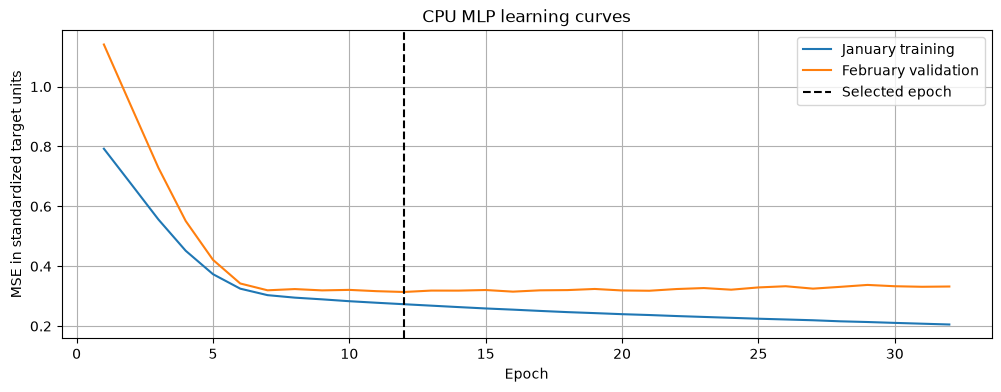

In [4]:
fig, ax = plt.subplots()
ax.plot(result.history.epoch, result.history.train_mse_scaled, label='January training')
ax.plot(result.history.epoch, result.history.validation_mse_scaled, label='February validation')
ax.axvline(result.best_epoch, color='black', linestyle='--', label='Selected epoch')
ax.set(xlabel='Epoch', ylabel='MSE in standardized target units', title='CPU MLP learning curves')
ax.legend(); plt.show()

## Compare measured errors on the same target hours
MAE and RMSE use rides/hour; WAPE is total absolute error divided by total actual demand, expressed as a percentage. Predictions are inverse-transformed to demand units and clipped at zero under the same predeclared physical constraint used by XGBoost.

We calculate the seasonal baselines with the existing evaluator. XGBoost metrics are loaded from the previous measured experiment with matching source-manifest provenance; XGBoost is not retrained here. Compare all three metrics rather than assuming a neural network will improve them.

In [5]:
baseline_tables = []
for split, left, right in [('validation', VALIDATION_START, TEST_START), ('test', TEST_START, END)]:
    _, scores = evaluate_midnights(series, left, right)
    baseline_tables.append(scores.assign(split=split, model=scores.lag_hours.map({24: 'Lag 24', 168: 'Lag 168'})))
xgb_metrics = pd.DataFrame([row for row in xgb_record['metrics'] if row['model'] == 'XGBoost'])
comparison = pd.concat([*baseline_tables, xgb_metrics, mlp_metrics], ignore_index=True)
comparison = comparison[['split', 'model', 'forecast_origins', 'target_hours', 'MAE', 'RMSE', 'WAPE_percent']]
display(comparison.round(3))
for split in ['validation', 'test']:
    scores = comparison[comparison.split.eq(split)].set_index('model')
    outcomes = ', '.join(f"{name}: {'lower' if scores.loc['PyTorch MLP', 'MAE'] < scores.loc[name, 'MAE'] else 'higher or equal'} MAE"
                         for name in ['Lag 24', 'Lag 168', 'XGBoost'])
    display(Markdown(f"**{split.title()} MLP MAE: {scores.loc['PyTorch MLP', 'MAE']:.2f}.** Compared with {outcomes}."))

,split,model,forecast_origins,target_hours,MAE,RMSE,WAPE_percent
0,validation,Lag 24,14,336,908.146,1454.002,27.897
1,validation,Lag 168,14,336,715.628,1202.430,21.983
2,test,Lag 24,15,360,759.853,1199.061,26.666
3,test,Lag 168,15,360,948.014,1438.950,33.269
4,validation,XGBoost,14,336,782.443,1242.431,24.035
5,test,XGBoost,15,360,649.272,994.204,22.785
6,validation,PyTorch MLP,14,336,782.260,1160.315,24.030
7,test,PyTorch MLP,15,360,622.371,973.487,21.841


**Validation MLP MAE: 782.26.** Compared with Lag 24: lower MAE, Lag 168: higher or equal MAE, XGBoost: lower MAE.

**Test MLP MAE: 622.37.** Compared with Lag 24: lower MAE, Lag 168: lower MAE, XGBoost: lower MAE.

## Actual versus predicted test demand
Each day's 24 predictions were issued at NYC midnight using a frozen January-trained model. This plot includes leap day. Large peak misses and day-specific errors can remain even if pooled average errors look favorable.

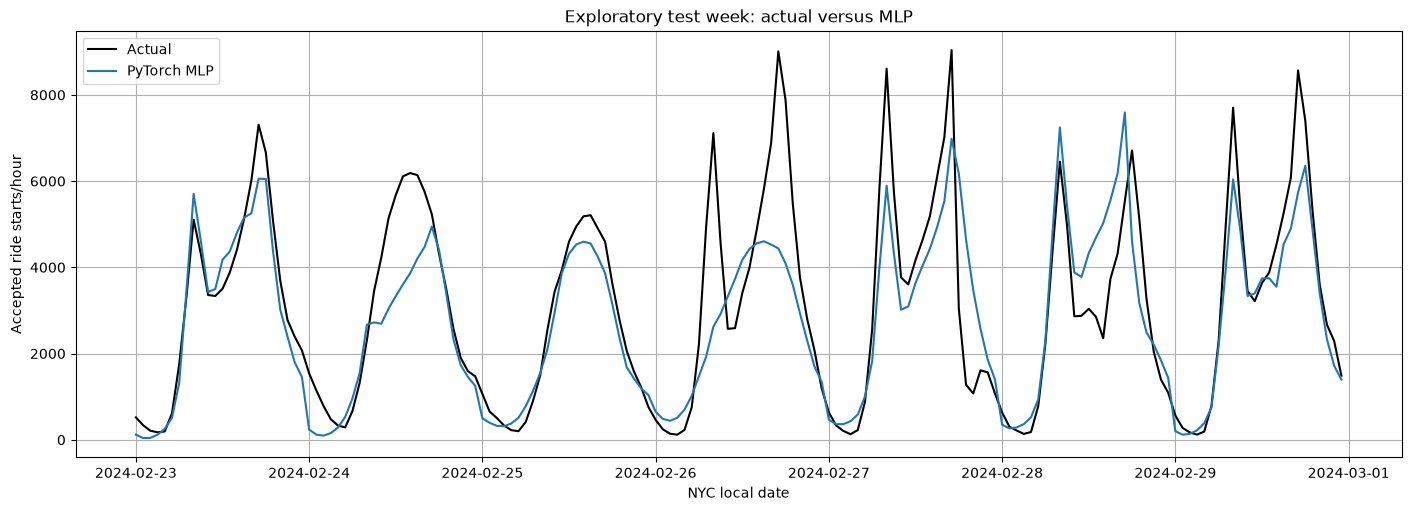

In [6]:
week = predictions[predictions.split.eq('test') & predictions.hour_start.ge(pd.Timestamp('2024-02-23', tz=LOCAL_ZONE))]
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
local_hours = week.hour_start.dt.tz_convert(LOCAL_ZONE)
ax.plot(local_hours, week.actual, color='black', label='Actual')
ax.plot(local_hours, week.prediction, label='PyTorch MLP')
ax.set(xlabel='NYC local date', ylabel='Accepted ride starts/hour', title='Exploratory test week: actual versus MLP')
ax.legend(); plt.show()

## Restore the saved model and issue a real next-day example
The checkpoint contains the best weights and January-fitted scaler statistics. Restoring it must reproduce predictions. We issue 24 elapsed-hour predictions for March 1 at NYC midnight using completed February history; no March actual demand is loaded or scored.

,hour_start,prediction,NYC_target_hour
0,2024-03-01 05:00:00+00:00,93.040039,2024-03-01 00:00:00-05:00
1,2024-03-01 06:00:00+00:00,17.976807,2024-03-01 01:00:00-05:00
2,2024-03-01 07:00:00+00:00,33.351074,2024-03-01 02:00:00-05:00
3,2024-03-01 08:00:00+00:00,109.709473,2024-03-01 03:00:00-05:00
4,2024-03-01 09:00:00+00:00,251.395752,2024-03-01 04:00:00-05:00
5,2024-03-01 10:00:00+00:00,518.519653,2024-03-01 05:00:00-05:00
6,2024-03-01 11:00:00+00:00,1457.835083,2024-03-01 06:00:00-05:00
7,2024-03-01 12:00:00+00:00,3953.744629,2024-03-01 07:00:00-05:00
8,2024-03-01 13:00:00+00:00,6363.791992,2024-03-01 08:00:00-05:00
9,2024-03-01 14:00:00+00:00,4919.762695,2024-03-01 09:00:00-05:00


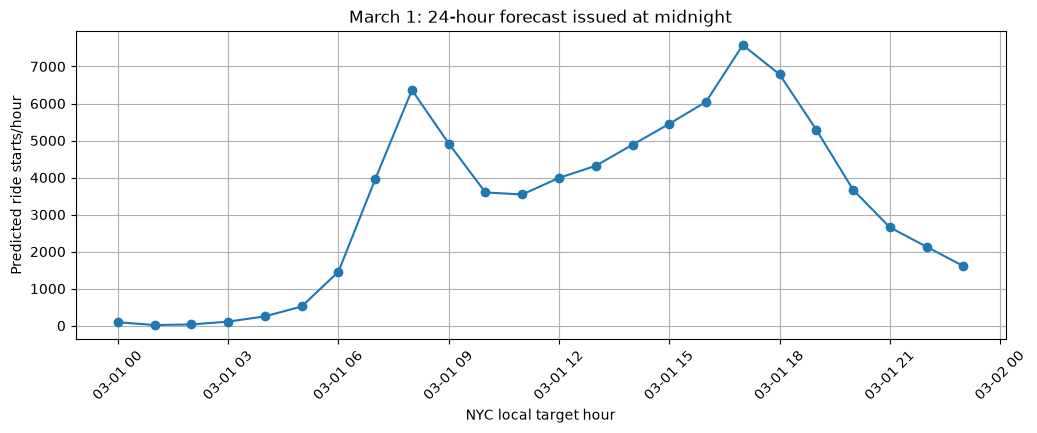

In [7]:
restored = load_mlp(result.checkpoint_path)
features = forecast_features(series, TEST_START)[FEATURES]
np.testing.assert_array_equal(result.forecaster.predict(features), restored.predict(features))
example = forecast_next_day(restored, series.loc[series.index < END], END)
example_table = example[['hour_start', 'prediction']].copy()
example_table['NYC_target_hour'] = example_table.hour_start.dt.tz_convert(LOCAL_ZONE)
display(example_table)
fig, ax = plt.subplots()
ax.plot(example_table.NYC_target_hour, example_table.prediction, marker='o')
ax.set(xlabel='NYC local target hour', ylabel='Predicted ride starts/hour', title='March 1: 24-hour forecast issued at midnight')
plt.xticks(rotation=45); plt.show()

## Interpretation and limitations
This model has only 576 training rows and nine calendar/lag features. It cannot account directly for weather or holidays. Inspect training/validation loss and held-period peak errors before labeling a fit as under- or overfitting. Lower training loss alone is not a forecasting improvement.

February test data have already been inspected for seasonal baselines and XGBoost: all comparisons are exploratory development evidence, with no claim of statistical significance or an untouched final test. No hyperparameters are retuned after observing these results. The final 24-month evaluation plan is unchanged. CPU seeds and deterministic kernels improve same-environment reproducibility; exact results are not guaranteed across versions or devices.

**Measured outcome:** the selected epoch was 12; training stopped at epoch 32. Selected training/validation scaled MSE were 0.273021 and 0.313892. At epoch 32 training MSE fell to 0.205272 while validation MSE increased to 0.332167, consistent with mild overfitting after the chosen epoch. Validation MAE 782.26 is almost tied with XGBoost 782.44 and remains above lag 168 (715.63). Test MAE 622.37 is lower than XGBoost (649.27) and both baselines. This is a measured exploratory result, not a claim of significant or general superiority.

In [8]:
record = {
    'exploratory_development_experiment': True, 'test_previously_inspected': True,
    'versions': versions, 'provenance': provenance,
    'architecture': '9 -> 32 ReLU -> 16 ReLU -> 1', 'settings': result.settings,
    'training_rows': result.training_rows, 'dropped_training_rows': result.dropped_training_rows,
    'epochs_run': len(result.history), 'best_epoch': result.best_epoch,
    'training_duration_seconds': result.duration_seconds,
    'best_train_mse_scaled': float(best.train_mse_scaled),
    'best_validation_mse_scaled': float(best.validation_mse_scaled),
    'target_mean': result.forecaster.target_scaler.mean_.tolist(),
    'target_scale': result.forecaster.target_scaler.scale_.tolist(),
    'checkpoint_relative_path': str(result.checkpoint_path.relative_to(ROOT)),
    'metrics': comparison.to_dict(orient='records'),
    'example_forecast': example_table.assign(hour_start=example_table.hour_start.astype(str),
                            NYC_target_hour=example_table.NYC_target_hour.astype(str)).to_dict(orient='records'),
}
(result_dir / 'experiment.json').write_text(json.dumps(record, indent=2, default=str) + '\n')
result.history.to_csv(result_dir / 'loss_history.csv', index=False)
print('Measured outputs:', result_dir.relative_to(ROOT))

Measured outputs: outputs/phase3-pytorch-mlp-jan-feb-2024/run-20261012T125502822756Z
